# Project 3 - Portfolio and Execution Simulation

This notebook combines the stage-two strategies into a simple institutional-style portfolio.

We will work in five blocks:
1. rebuild the three strategy return streams,
2. combine them with inverse-volatility weights as Method A,
3. compare against Markowitz mean-variance optimization as Method B,
4. add execution constraints and costs,
5. run robustness checks.

In [321]:
from pathlib import Path  # Work with repository paths safely.
import sys  # Let us modify the import path for notebook execution.

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()  # Find the repository root.

if str(project_root) not in sys.path:  # Only append the path once.
    sys.path.append(str(project_root))  # Make src/ importable from the notebook.

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[autoreload of src.utils.config failed: Traceback (most recent call last):
  File "/Applications/anaconda3/lib/python3.9/site-packages/IPython/extensions/autoreload.py", line 245, in check
    superreload(m, reload, self.old_objects)
  File "/Applications/anaconda3/lib/python3.9/site-packages/IPython/extensions/autoreload.py", line 410, in superreload
    update_generic(old_obj, new_obj)
  File "/Applications/anaconda3/lib/python3.9/site-packages/IPython/extensions/autoreload.py", line 347, in update_generic
    update(a, b)
  File "/Applications/anaconda3/lib/python3.9/site-packages/IPython/extensions/autoreload.py", line 317, in update_class
    update_instances(old, new)
  File "/Applications/anaconda3/lib/python3.9/site-packages/IPython/extensions/autoreload.py", line 280, in update_instances
    ref.__class__ = new
  File "<string>", line 4, in __setattr__
dataclasses.FrozenInstanceError: cannot assign to field '__class__'
]


In [322]:
import matplotlib.pyplot as plt  # Plot portfolio growth and robustness diagnostics.
import pandas as pd  # Assemble tables of returns and metrics.

from src.backtest.engine import drawdown_curve, equity_curve, performance_metrics, positions_to_strategy_returns, rolling_sharpe_ratio  # Backtest and evaluation helpers.
from src.execution.costs import apply_turnover_cap  # Limit how much the portfolio can trade in one step.
from src.models.ou import compute_spread_zscore  # Standardize the spread for the pair strategy.
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes  # Build the regime signal.
from src.models.volatility import fit_random_forest_volatility_model, predict_random_forest_volatility, split_train_test  # Build the volatility timing signal.
from src.strategies.pairs_trading import pairs_positions_from_zscore  # Translate pair signals into positions.
from src.strategies.regime_switching import map_regimes_to_labels, regime_based_positions  # Translate regimes into exposures.
from src.strategies.volatility_timing import inverse_volatility_position  # Translate volatility into position size.
from src.utils.config import COST_CONFIG, DATA_CONFIG  # Shared project settings.
from src.utils.data_loader import build_market_data_bundle, build_spread, make_volatility_features  # Shared data engineering helpers.

from src.portfolio.construction import (
    CONCENTRATION_LAMBDA,
    MARKOWITZ_VARIANTS,
    apply_volatility_target,
    combine_strategy_returns,
    inverse_volatility_weights,
    markowitz_avg_weights_table,
    markowitz_max_sharpe_weights,
    markowitz_metrics_table,
    markowitz_variant_weights,
    run_markowitz_variants,
    run_markowitz_variants_pre_cost,
)

Markowitz pipeline helpers (`run_markowitz_variants_pre_cost`, `run_markowitz_variants`, `markowitz_metrics_table`, `markowitz_avg_weights_table`) are defined in `src/portfolio/construction.py` and imported in the cell above.

## Step 1 - Rebuild the three strategy return streams

We rebuild the strategy legs inside this notebook so the portfolio construction is fully transparent and reproducible.

In [323]:
market_data = build_market_data_bundle()  # Download the shared price and return dataset.
prices = market_data.prices  # Save prices under a short variable name.
returns = market_data.log_returns  # Save log returns for later strategy backtests.
realized_vol = market_data.realized_volatility  # Save realized volatility for forecasting and regime work.

benchmark_asset = DATA_CONFIG.benchmark_symbol  # Use SPY as the main directional asset.
benchmark_returns = returns[benchmark_asset]  # Pull out the SPY return stream.
benchmark_realized_vol = realized_vol[benchmark_asset].reindex(benchmark_returns.index)  # Align SPY volatility to the SPY return index.

In [324]:
volatility_features = make_volatility_features(benchmark_returns, benchmark_realized_vol)  # Build the feature table for volatility timing.
train_features, test_features = split_train_test(volatility_features)  # Split the features into train and test sets.
vol_model = fit_random_forest_volatility_model(train_features)  # Fit the volatility forecast model.
vol_signal = predict_random_forest_volatility(vol_model, test_features)  # Predict future volatility.
vol_positions = inverse_volatility_position(vol_signal, benchmark_asset)  # Translate lower predicted volatility into larger exposure.
vol_backtest = positions_to_strategy_returns(vol_positions, returns[[benchmark_asset]], COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps)  # Backtest the volatility strategy.

In [325]:
asset_a, asset_b = DATA_CONFIG.pair_symbols  # Unpack the configured pair.
spread_frame = build_spread(prices[asset_a], prices[asset_b])  # Estimate the hedge ratio and construct the spread.
spread_zscore = compute_spread_zscore(spread_frame["spread"])  # Standardize the spread for entry and exit rules.
pairs_positions = pairs_positions_from_zscore(spread_zscore, asset_a, asset_b)  # Convert the z-score into pair positions.
pairs_backtest = positions_to_strategy_returns(pairs_positions, returns[[asset_a, asset_b]], COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps)  # Backtest the pair strategy.

regime_features = build_regime_features(benchmark_returns, benchmark_realized_vol)  # Build the HMM feature matrix.
hmm_model = fit_hmm_regime_model(regime_features)  # Fit the Hidden Markov Model.
regimes = infer_regimes(hmm_model, regime_features)  # Infer one latent state per date.
regime_table = map_regimes_to_labels(regimes, benchmark_returns)  # Interpret each raw state as bull, sideways, or crisis.
regime_positions = regime_based_positions(regime_table["regime_label"], benchmark_asset)  # Convert labels into tradable weights.
regime_backtest = positions_to_strategy_returns(regime_positions, returns[[benchmark_asset]], COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps)  # Backtest the regime strategy.

## Step 2 - Method A: Inverse-volatility portfolio

We treat each strategy return stream like an asset and allocate more weight to the strategies that have been less volatile recently.

This is the simpler portfolio method. It only uses risk estimates, not expected returns.

In [326]:
strategy_returns = pd.DataFrame({  # Collect each stage-two strategy in one return table.
    "volatility_timing": vol_backtest["net_return"],
    # "pairs_trading": pairs_backtest["net_return"],
    "regime_switching": regime_backtest["net_return"],
}).dropna(how="any")

portfolio_weights = inverse_volatility_weights(strategy_returns)  # Estimate inverse-volatility strategy weights. 
portfolio_weights.tail() # Inspect the most recent allocation mix.
# strategy_returns.tail()

,volatility_timing,regime_switching
Date,,
2025-12-22,0.356956,0.643044
2025-12-23,0.357568,0.642432
2025-12-24,0.357563,0.642437
2025-12-26,0.356862,0.643138
2025-12-29,0.356994,0.643006


In [327]:
# Average weights across the strategies
(portfolio_weights.mean() * 100).round(1).to_frame("avg_weight_%")


,avg_weight_%
volatility_timing,31.4
regime_switching,68.6


In [328]:
raw_portfolio_return = combine_strategy_returns(strategy_returns, portfolio_weights)  # Form the weighted portfolio before any overlay.
raw_portfolio_return.tail()

Date
2025-12-22    0.006394
2025-12-23    0.004884
2025-12-24    0.003708
2025-12-26   -0.000125
2025-12-29   -0.004183
Name: portfolio_return, dtype: float64

In [329]:
vol_targeted_return = apply_volatility_target(raw_portfolio_return, COST_CONFIG.target_portfolio_vol)  # Scale the portfolio toward the target volatility.
vol_targeted_return.tail()

Date
2025-12-22    0.006136
2025-12-23    0.004692
2025-12-24    0.003559
2025-12-26   -0.000120
2025-12-29   -0.004066
Name: vol_targeted_return, dtype: float64

In [330]:

pd.Series(performance_metrics(vol_targeted_return), name="Vol-targeted portfolio").to_frame()  # Show the main institutional-style performance metrics.

,Vol-targeted portfolio
sharpe_ratio,1.213916
sortino_ratio,1.538364
cagr,0.129995
max_drawdown,-0.104445
calmar_ratio,1.244631
volatility,0.105273
var_95,0.009837
expected_shortfall_95,0.015657


## Step 3 - Method B: Markowitz mean-variance portfolio

Markowitz optimization uses both expected returns and the covariance matrix.

Here we use a rolling long-only max-Sharpe version with five specs compared side by side:
baseline, Ledoit–Wolf shrinkage, 70% weight cap, shrinkage + cap, and a standalone concentration penalty (`max Sharpe − λ Σ w_i²`).

In [331]:
# Pre-cost Markowitz variants (aligned metrics across variants on shared dates).
markowitz_pre_cost = run_markowitz_variants_pre_cost(strategy_returns)

markowitz_weights = markowitz_pre_cost["markowitz_baseline"]["weights"]
markowitz_return = combine_strategy_returns(strategy_returns, markowitz_weights)
markowitz_vol_targeted_return = markowitz_pre_cost["markowitz_baseline"]["returns"]

markowitz_pre_cost_metrics = markowitz_metrics_table(markowitz_pre_cost)
markowitz_pre_cost_metrics

,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
sharpe_ratio,1.170100,1.168929,1.224655,1.234112,1.200963
sortino_ratio,1.367478,1.374003,1.487433,1.502155,1.451165
cagr,0.126692,0.126608,0.131219,0.132469,0.128269
max_drawdown,-0.093697,-0.093620,-0.101782,-0.101635,-0.105027
calmar_ratio,1.352136,1.352356,1.289214,1.303374,1.221294
volatility,0.106861,0.106908,0.105233,0.105330,0.105125
var_95,0.010030,0.010010,0.009842,0.009867,0.010029
expected_shortfall_95,0.016915,0.016815,0.016189,0.016188,0.016222


In [332]:
for name, res in markowitz_pre_cost.items():
    print(f"\n=== {name} (pre-cost) ===")
    display((res["weights"].tail() * 100).round(1))


=== markowitz_baseline (pre-cost) ===


,volatility_timing,regime_switching
2025-12-22,0.0,100.0
2025-12-23,0.0,100.0
2025-12-24,0.0,100.0
2025-12-26,0.0,100.0
2025-12-29,0.0,100.0



=== markowitz_shrinkage (pre-cost) ===


,volatility_timing,regime_switching
2025-12-22,15.5,84.5
2025-12-23,13.7,86.3
2025-12-24,7.1,92.9
2025-12-26,4.8,95.2
2025-12-29,0.4,99.6



=== markowitz_cap70 (pre-cost) ===


,volatility_timing,regime_switching
2025-12-22,30.0,70.0
2025-12-23,30.0,70.0
2025-12-24,30.0,70.0
2025-12-26,30.0,70.0
2025-12-29,30.0,70.0



=== markowitz_shrinkage_cap70 (pre-cost) ===


,volatility_timing,regime_switching
2025-12-22,30.0,70.0
2025-12-23,30.0,70.0
2025-12-24,30.0,70.0
2025-12-26,30.0,70.0
2025-12-29,30.0,70.0



=== markowitz_concentration (pre-cost) ===


,volatility_timing,regime_switching
2025-12-22,30.5,69.5
2025-12-23,28.4,71.6
2025-12-24,23.2,76.8
2025-12-26,21.8,78.2
2025-12-29,20.3,79.7


In [333]:
# Average weights across the strategies
# (markowitz_weights.mean() * 100).round(1).to_frame("avg_weight_%")
markowitz_avg_weights_table(markowitz_pre_cost)

,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
volatility_timing,47.7,50.0,48.2,49.2,42.6
regime_switching,52.3,50.0,51.8,50.8,57.4


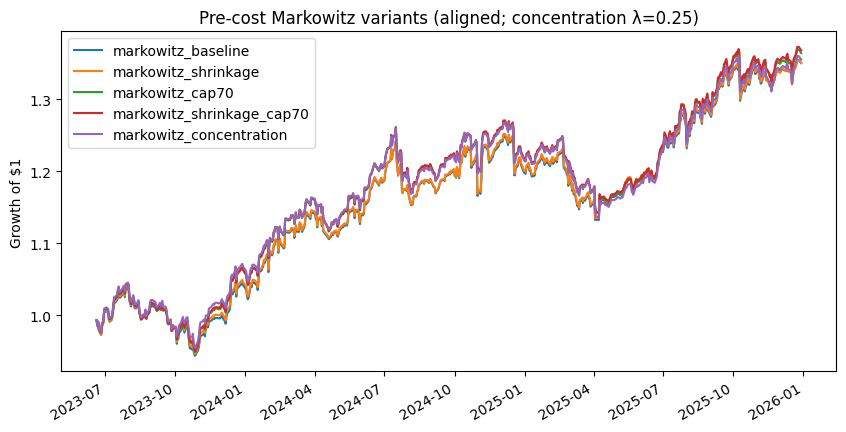

In [334]:
# Aligned pre-cost comparison: inverse-vol + all Markowitz variants on shared dates.
pre_cost_compare = pd.DataFrame(
    {
        "inverse_volatility": vol_targeted_return,
        **{name: res["returns"] for name, res in markowitz_pre_cost.items()},
    }
).dropna(how="any")

pre_cost_metrics = pd.DataFrame(
    {col: performance_metrics(pre_cost_compare[col]) for col in pre_cost_compare.columns}
)

markowitz_pre_cost_metrics = pre_cost_metrics[
    [name for name in MARKOWITZ_VARIANTS if name in pre_cost_metrics.columns]
]

pre_cost_metrics

# Pre-cost equity curves: all Markowitz specs on the same calendar.
pre_cost_compare[list(MARKOWITZ_VARIANTS)].apply(equity_curve).plot(
    figsize=(10, 5),
    title=f"Pre-cost Markowitz variants (aligned; concentration λ={CONCENTRATION_LAMBDA})",
)
plt.ylabel("Growth of $1")
plt.show()

## Step 4 - Add execution realism

An ideal optimizer may want to trade too much. Here we cap turnover at the portfolio-weight level and then re-run both portfolio methods with more realistic weights.

In [335]:
capped_inverse_vol_weights = apply_turnover_cap(portfolio_weights, COST_CONFIG.turnover_cap)

inverse_vol_backtest = positions_to_strategy_returns(
    capped_inverse_vol_weights,
    strategy_returns,
    COST_CONFIG.transaction_cost_bps,
    COST_CONFIG.slippage_bps,
)
realistic_portfolio_return = apply_volatility_target(
    inverse_vol_backtest["net_return"],
    COST_CONFIG.target_portfolio_vol,
)

markowitz_realistic = run_markowitz_variants(strategy_returns)

capped_markowitz_weights = markowitz_realistic["markowitz_baseline"]["weights_capped"]
realistic_markowitz_return = markowitz_realistic["markowitz_baseline"]["returns"]

realistic_compare = pd.DataFrame(
    {
        "inverse_volatility": realistic_portfolio_return,
        **{name: res["returns"] for name, res in markowitz_realistic.items()},
    }
).dropna(how="any")

realistic_metrics = pd.DataFrame(
    {col: performance_metrics(realistic_compare[col]) for col in realistic_compare.columns}
)
realistic_metrics

,inverse_volatility,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
sharpe_ratio,1.250592,0.983301,0.972115,1.157836,1.148586,1.109750
sortino_ratio,1.518272,1.160757,1.149356,1.408633,1.394266,1.345053
cagr,0.134523,0.103989,0.102762,0.122950,0.122116,0.117160
max_drawdown,-0.104679,-0.114617,-0.114462,-0.110795,-0.110664,-0.112961
calmar_ratio,1.285108,0.907273,0.897783,1.109701,1.103488,1.037175
volatility,0.105398,0.106400,0.106491,0.104940,0.105158,0.104816
var_95,0.009382,0.010585,0.010547,0.009921,0.009921,0.010274
expected_shortfall_95,0.016025,0.016978,0.016949,0.016322,0.016369,0.016240


In [336]:
realistic_weight_summary = markowitz_avg_weights_table(markowitz_realistic)
realistic_weight_summary.loc["inverse_volatility"] = capped_inverse_vol_weights.mean() * 100
realistic_weight_summary.sort_index().round(1)

,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
inverse_volatility,NaN,NaN,NaN,NaN,NaN
regime_switching,52.1,49.7,51.8,50.8,57.4
volatility_timing,47.9,50.3,48.2,49.2,42.6


## Step 5 - Portfolio OOS (walk-forward)

Strategy signals are rebuilt with expanding-window refits (same walk-forward machinery as notebook 2). Portfolio weights, turnover caps, and vol targeting are then applied to those OOS strategy returns only. In-sample metrics are recomputed on the same OOS calendar for a fair comparison.

In [337]:
from src.backtest.walk_forward import (
    walk_forward_pairs_positions,
    walk_forward_regime_positions,
    walk_forward_volatility_positions,
)

wf_min_train = max(DATA_CONFIG.annualization_factor * 2, len(volatility_features.index) // 5)
wf_test = DATA_CONFIG.rolling_vol_window

vol_wf_positions = walk_forward_volatility_positions(
    volatility_features,
    benchmark_asset,
    min_train_observations=wf_min_train,
    test_observations=wf_test,
)
regime_wf_positions = walk_forward_regime_positions(
    regime_features,
    benchmark_returns,
    benchmark_asset,
    min_train_observations=wf_min_train,
    test_observations=wf_test,
)

vol_wf_bt = positions_to_strategy_returns(
    vol_wf_positions,
    returns[[benchmark_asset]],
    COST_CONFIG.transaction_cost_bps,
    COST_CONFIG.slippage_bps,
)
regime_wf_bt = positions_to_strategy_returns(
    regime_wf_positions,
    returns[[benchmark_asset]],
    COST_CONFIG.transaction_cost_bps,
    COST_CONFIG.slippage_bps,
)

wf_return_map = {
    "volatility_timing": vol_wf_bt["net_return"],
    "regime_switching": regime_wf_bt["net_return"],
}
if "pairs_trading" in strategy_returns.columns:
    pairs_wf_positions = walk_forward_pairs_positions(
        prices[asset_a],
        prices[asset_b],
        asset_a,
        asset_b,
        min_train_observations=wf_min_train,
        test_observations=wf_test,
        zscore_window=DATA_CONFIG.rolling_vol_window,
    )
    pairs_wf_bt = positions_to_strategy_returns(
        pairs_wf_positions,
        returns[[asset_a, asset_b]],
        COST_CONFIG.transaction_cost_bps,
        COST_CONFIG.slippage_bps,
    )
    wf_return_map["pairs_trading"] = pairs_wf_bt["net_return"]

strategy_returns_wf = pd.DataFrame(
    {name: wf_return_map[name] for name in strategy_returns.columns if name in wf_return_map}
).dropna(how="any")
strategy_returns_wf.tail()

,volatility_timing,regime_switching
Date,,
2025-12-05,0.001537,0.000664
2025-12-08,-0.002465,-0.001053
2025-12-09,-0.000727,-0.000302
2025-12-10,0.005511,0.002314
2025-12-11,0.002140,0.000813


In [338]:
wf_iv_weights = inverse_volatility_weights(strategy_returns_wf)
wf_iv_capped = apply_turnover_cap(wf_iv_weights, COST_CONFIG.turnover_cap)
wf_iv_return = apply_volatility_target(
    positions_to_strategy_returns(
        wf_iv_capped,
        strategy_returns_wf,
        COST_CONFIG.transaction_cost_bps,
        COST_CONFIG.slippage_bps,
    )["net_return"],
    COST_CONFIG.target_portfolio_vol,
)

markowitz_oos = run_markowitz_variants(strategy_returns_wf)
wf_mw_return = markowitz_oos["markowitz_baseline"]["returns"]

oos_compare = pd.DataFrame(
    {
        "inverse_volatility": wf_iv_return,
        **{name: res["returns"] for name, res in markowitz_oos.items()},
    }
).dropna(how="any")
wf_compare_dates = oos_compare.index

oos_compare.tail()


,inverse_volatility,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
2025-12-05,0.000989,0.001161,0.001161,0.001107,0.001107,0.001026
2025-12-08,-0.001581,-0.001863,-0.001864,-0.001773,-0.001773,-0.001686
2025-12-09,-0.000461,-0.000549,-0.000549,-0.000521,-0.000521,-0.000504
2025-12-10,0.003507,0.004166,0.004168,0.003957,0.003957,0.003712
2025-12-11,0.001323,0.001631,0.001631,0.001530,0.001530,0.001446


In [339]:

is_oos_columns = {}
for col in oos_compare.columns:
    is_oos_columns[(col, "in-sample")] = pd.Series(
        performance_metrics(realistic_compare[col].reindex(wf_compare_dates).dropna()),
    )
    is_oos_columns[(col, "OOS")] = pd.Series(
        performance_metrics(oos_compare[col]),
    )

portfolio_is_vs_oos = pd.DataFrame(is_oos_columns)
portfolio_is_vs_oos.columns.names = ["method", "evaluation"]
portfolio_is_vs_oos.index.name = "metric"
portfolio_is_vs_oos

method                inverse_volatility           markowitz_baseline  \
evaluation                     in-sample       OOS          in-sample   
metric                                                                  
sharpe_ratio                    1.252348  0.788544           0.985415   
sortino_ratio                   1.513718  0.872943           1.158832   
cagr                            0.134910  0.082319           0.104509   
max_drawdown                   -0.104679 -0.175118          -0.114617   
calmar_ratio                    1.288806  0.470076           0.911812   
volatility                      0.105535  0.107761           0.106681   
var_95                          0.009368  0.009598           0.010545   
expected_shortfall_95           0.015955  0.017134           0.016974   

method                          markowitz_shrinkage           markowitz_cap70  \
evaluation                  OOS           in-sample       OOS       in-sample   
metric                                                                          
sharpe_ratio           0.845577            0.977123  0.852470        1.162731   
sortino_ratio          0.992006            1.151044  1.005505        1.408901   
cagr                   0.088634            0.103640  0.089405        0.123740   
max_drawdown          -0.171337           -0.114462 -0.162698       -0.110795   
calmar_ratio           0.517306            0.905457  0.549514        1.116830   
volatility             0.107283            0.106793  0.107241        0.105119   
var_95                 0.010003            0.010564  0.009970        0.009908   
expected_shortfall_95  0.017032            0.016949  0.017030        0.016282   

method                          markowitz_shrinkage_cap70            \
evaluation                  OOS                 in-sample       OOS   
metric                                                                
sharpe_ratio           0.835414                  1.156553  0.839570   
sortino_ratio          0.974215                  1.398546  0.980629   
cagr                   0.087141                  0.123307  0.087630   
max_drawdown          -0.144209                 -0.110664 -0.141500   
calmar_ratio           0.604270                  1.114252  0.619294   
volatility             0.106906                  0.105371  0.106913   
var_95                 0.009825                  0.009907  0.009829   
expected_shortfall_95  0.017010                  0.016338  0.016997   

method                markowitz_concentration            
evaluation                          in-sample       OOS  
metric                                                   
sharpe_ratio                         1.114856  0.835284  
sortino_ratio                        1.345919  0.989954  
cagr                                 0.117985  0.086838  
max_drawdown                        -0.112961 -0.135731  
calmar_ratio                         1.044480  0.639782  
volatility                           0.105018  0.106533  
var_95                               0.010216  0.009859  
expected_shortfall_95                0.016216  0.016779

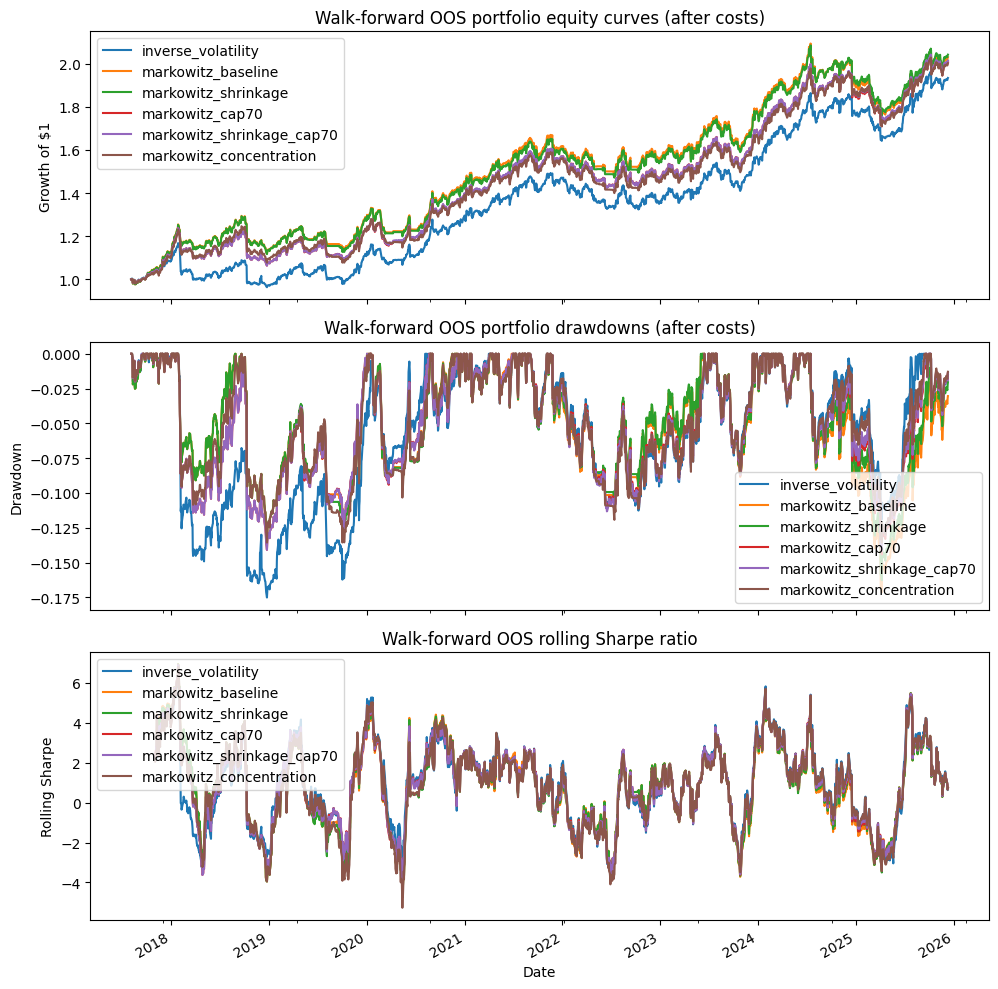

In [340]:
# OOS metrics and plots use the same aligned frame as portfolio_is_vs_oos.
rolling_sharpe_oos = oos_compare.apply(rolling_sharpe_ratio)

fig_oos, axes_oos = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

oos_compare.apply(equity_curve).plot(
    ax=axes_oos[0],
    title="Walk-forward OOS portfolio equity curves (after costs)",
)
axes_oos[0].set_ylabel("Growth of $1")

oos_compare.apply(
    lambda column: drawdown_curve(equity_curve(column))
).plot(
    ax=axes_oos[1],
    title="Walk-forward OOS portfolio drawdowns (after costs)",
)
axes_oos[1].set_ylabel("Drawdown")

rolling_sharpe_oos.plot(
    ax=axes_oos[2],
    title="Walk-forward OOS rolling Sharpe ratio",
)
axes_oos[2].set_ylabel("Rolling Sharpe")
axes_oos[2].set_xlabel("Date")

fig_oos.tight_layout()
plt.show()

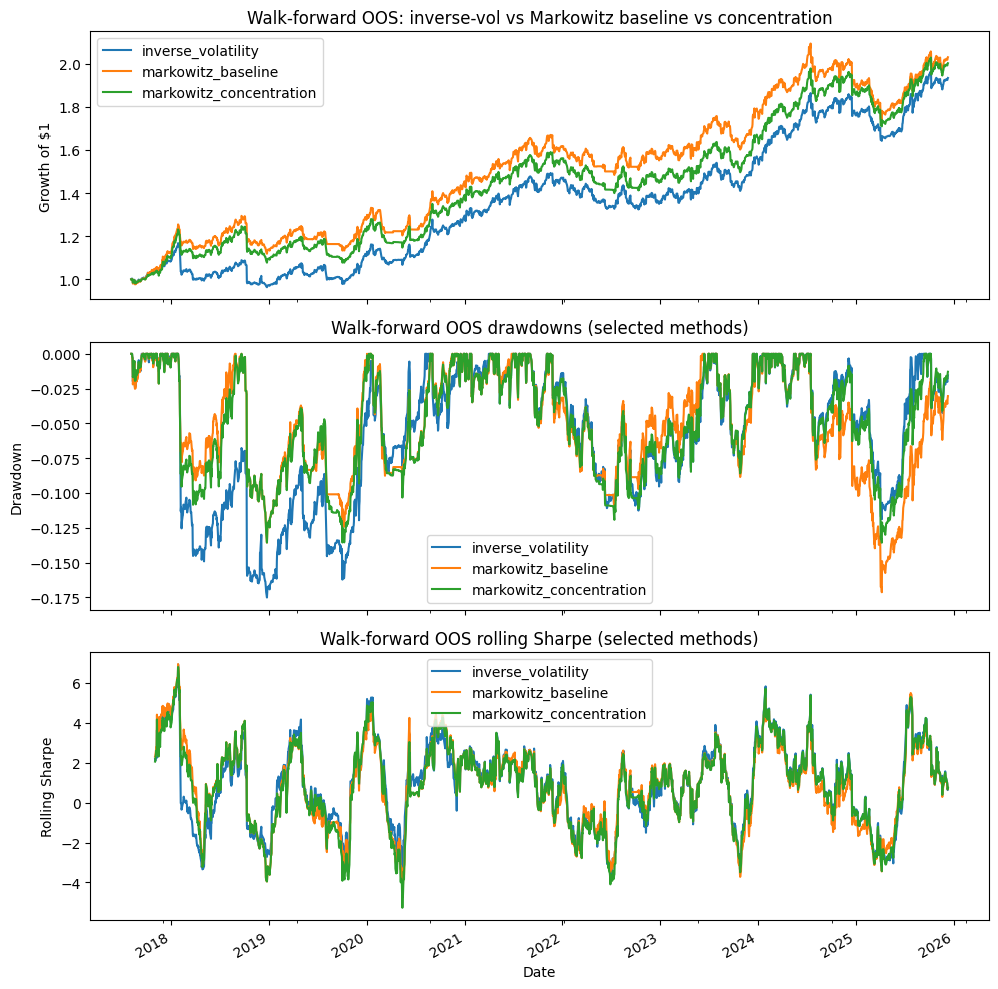

In [341]:
oos_focus = oos_compare[
    ["inverse_volatility", "markowitz_baseline", "markowitz_concentration"]
]
rolling_sharpe_oos_focus = oos_focus.apply(rolling_sharpe_ratio)

fig_oos_focus, axes_oos_focus = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

oos_focus.apply(equity_curve).plot(
    ax=axes_oos_focus[0],
    title="Walk-forward OOS: inverse-vol vs Markowitz baseline vs concentration",
)
axes_oos_focus[0].set_ylabel("Growth of $1")

oos_focus.apply(
    lambda column: drawdown_curve(equity_curve(column))
).plot(
    ax=axes_oos_focus[1],
    title="Walk-forward OOS drawdowns (selected methods)",
)
axes_oos_focus[1].set_ylabel("Drawdown")

rolling_sharpe_oos_focus.plot(
    ax=axes_oos_focus[2],
    title="Walk-forward OOS rolling Sharpe (selected methods)",
)
axes_oos_focus[2].set_ylabel("Rolling Sharpe")
axes_oos_focus[2].set_xlabel("Date")

fig_oos_focus.tight_layout()
plt.show()

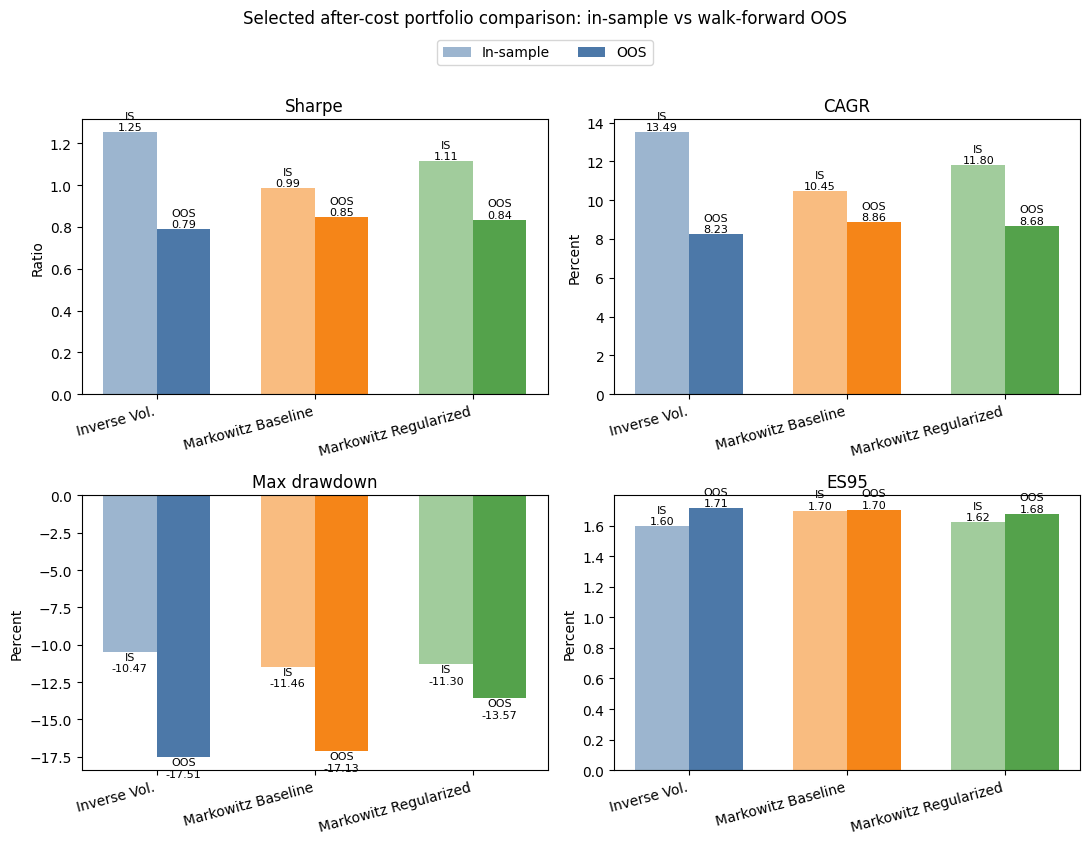

In [346]:
focus_cols = ["inverse_volatility", "markowitz_baseline", "markowitz_concentration"]
method_labels = {
    "inverse_volatility": "Inverse Vol.",
    "markowitz_baseline": "Markowitz Baseline",
    "markowitz_concentration": "Markowitz Regularized",
}

is_focus = realistic_compare[focus_cols].reindex(wf_compare_dates).dropna(how="any")
oos_focus_returns = oos_compare[focus_cols]

is_metrics_focus = pd.DataFrame(
    {col: performance_metrics(is_focus[col]) for col in focus_cols}
)
oos_metrics_focus = pd.DataFrame(
    {col: performance_metrics(oos_focus_returns[col]) for col in focus_cols}
)

metric_panels = [
    ("sharpe_ratio", "Sharpe", "Ratio", False),
    ("cagr", "CAGR", "Percent", True),
    ("max_drawdown", "Max drawdown", "Percent", True),
    ("expected_shortfall_95", "ES95", "Percent", True),
]

x = list(range(len(focus_cols)))
bar_width = 0.34
method_colors = ["#4C78A8", "#F58518", "#54A24B"]

fig_focus_metrics, axes_focus_metrics = plt.subplots(2, 2, figsize=(11, 8))
for ax, (metric_key, title, ylabel, as_percent) in zip(
    axes_focus_metrics.flat, metric_panels
):
    is_values = is_metrics_focus.loc[metric_key, focus_cols].to_numpy()
    oos_values = oos_metrics_focus.loc[metric_key, focus_cols].to_numpy()
    if as_percent:
        is_values = is_values * 100
        oos_values = oos_values * 100

    for idx, (is_val, oos_val) in enumerate(zip(is_values, oos_values)):
        ax.bar(
            x[idx] - bar_width / 2,
            is_val,
            bar_width,
            color=method_colors[idx],
            alpha=0.55,
            label="In-sample" if idx == 0 else None,
        )
        ax.bar(
            x[idx] + bar_width / 2,
            oos_val,
            bar_width,
            color=method_colors[idx],
            alpha=1.0,
            label="OOS" if idx == 0 else None,
        )
        is_va = "top" if is_val < 0 else "bottom"
        oos_va = "top" if oos_val < 0 else "bottom"
        ax.text(
            x[idx] - bar_width / 2,
            is_val,
            f"IS\n{is_val:.2f}",
            ha="center",
            va=is_va,
            fontsize=8,
        )
        ax.text(
            x[idx] + bar_width / 2,
            oos_val,
            f"OOS\n{oos_val:.2f}",
            ha="center",
            va=oos_va,
            fontsize=8,
        )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels([method_labels[col] for col in focus_cols], rotation=15, ha="right")
    ax.axhline(0.0, color="black", linewidth=0.8, alpha=0.3)

handles, labels = axes_focus_metrics[0, 0].get_legend_handles_labels()
fig_focus_metrics.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig_focus_metrics.suptitle(
    "Selected after-cost portfolio comparison: in-sample vs walk-forward OOS",
    y=1.05,
)
fig_focus_metrics.tight_layout()
plt.show()

## Step 6 - Stress testing and robustness

We now ask four questions:
1. how correlated are the strategies,
2. how stable is the inverse-volatility Sharpe ratio through time,
3. how does Markowitz compare after costs,
4. what happens during the crisis-like HMM regime?

In [343]:
strategy_correlation = strategy_returns.corr()
crisis_mask = regime_table["regime_label"].reindex(realistic_compare.index).eq("crisis")

crisis_metrics = {
    "inverse_vol_crisis": performance_metrics(realistic_compare["inverse_volatility"][crisis_mask]),
    "inverse_vol_non_crisis": performance_metrics(realistic_compare["inverse_volatility"][~crisis_mask]),
}
for name in MARKOWITZ_VARIANTS:
    if name not in realistic_compare.columns:
        continue
    crisis_metrics[f"{name}_crisis"] = performance_metrics(realistic_compare[name][crisis_mask])
    crisis_metrics[f"{name}_non_crisis"] = performance_metrics(realistic_compare[name][~crisis_mask])

pd.concat(
    [
        strategy_correlation.stack().rename("correlation").to_frame().head(9),
        pd.DataFrame(crisis_metrics),
    ],
    axis=0,
)

,correlation,inverse_vol_crisis,inverse_vol_non_crisis,markowitz_baseline_crisis,markowitz_baseline_non_crisis,markowitz_shrinkage_crisis,markowitz_shrinkage_non_crisis,markowitz_cap70_crisis,markowitz_cap70_non_crisis,markowitz_shrinkage_cap70_crisis,markowitz_shrinkage_cap70_non_crisis,markowitz_concentration_crisis,markowitz_concentration_non_crisis
"(volatility_timing, volatility_timing)",1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"(volatility_timing, regime_switching)",0.81644,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"(regime_switching, volatility_timing)",0.81644,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"(regime_switching, regime_switching)",1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sharpe_ratio,NaN,-1.533355,1.375912,-1.401085,1.111764,-1.401085,1.099858,-1.639073,1.297220,-1.639073,1.287215,-1.495219,1.243172
sortino_ratio,NaN,-1.216239,1.705261,-1.219235,1.334826,-1.219235,1.322723,-1.350777,1.611278,-1.350777,1.594884,-1.282261,1.534585
cagr,NaN,-0.123224,0.151185,-0.137144,0.119488,-0.137144,0.118173,-0.144431,0.140360,-0.144431,0.139465,-0.136471,0.133555
max_drawdown,NaN,-0.012057,-0.084108,-0.022998,-0.099989,-0.022998,-0.100290,-0.018588,-0.092462,-0.018588,-0.092556,-0.017721,-0.090079
calmar_ratio,NaN,-10.220374,1.797521,-5.963183,1.195011,-5.963183,1.178320,-7.770151,1.518019,-7.770151,1.506822,-7.700903,1.482635
volatility,NaN,0.083513,0.106483,0.101643,0.106676,0.101643,0.106772,0.092579,0.105581,0.092579,0.105811,0.095143,0.105334


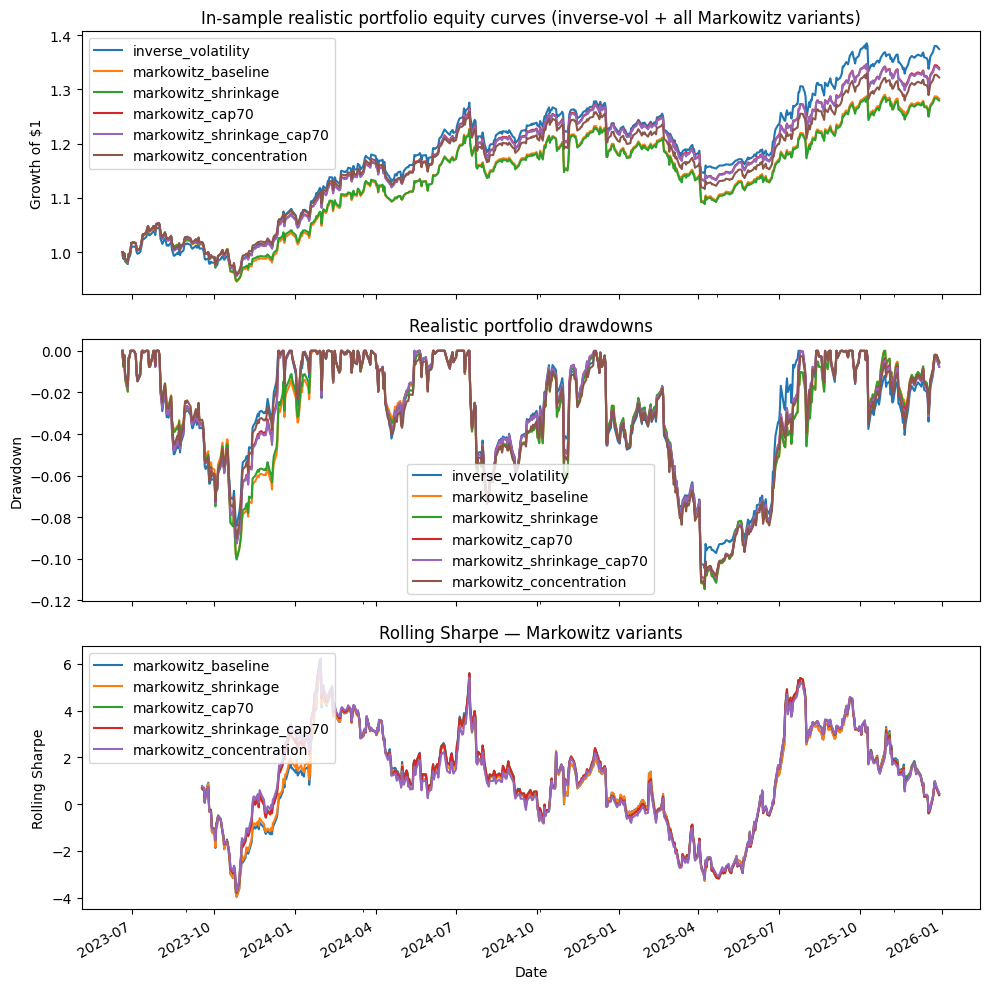

In [344]:
markowitz_realistic_compare = realistic_compare[
    [name for name in MARKOWITZ_VARIANTS if name in realistic_compare.columns]
]
rolling_sharpe_realistic = markowitz_realistic_compare.apply(rolling_sharpe_ratio)

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

realistic_compare.apply(equity_curve).plot(
    ax=axes[0],
    title="In-sample realistic portfolio equity curves (inverse-vol + all Markowitz variants)",
)
axes[0].set_ylabel("Growth of $1")

realistic_compare.apply(lambda column: drawdown_curve(equity_curve(column))).plot(
    ax=axes[1],
    title="Realistic portfolio drawdowns",
)
axes[1].set_ylabel("Drawdown")

rolling_sharpe_realistic.plot(ax=axes[2], title="Rolling Sharpe — Markowitz variants")
axes[2].set_ylabel("Rolling Sharpe")
axes[2].set_xlabel("Date")
fig.tight_layout()
plt.show()